In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

FEATURES_CSV = "data/features_lab2.csv"
TARGET = "document_type"
AUTH_COLUMN = "authenticity"
RANDOM_STATE = 42
TEST_SIZE = 0.2

df = pd.read_csv(FEATURES_CSV)
df[AUTH_COLUMN] = df[AUTH_COLUMN].fillna('not_applicable')

# Попереднє очищення та масштабування
for col in ['width', 'file_size_bytes']:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    df[col] = df[col].clip(lower=q1 - 1.5*iqr, upper=q3 + 1.5*iqr)

if 'mean_brightness' in df.columns:
    df = df.drop(columns=['mean_brightness'])

NUMERIC_COLS_SELECTED = ['width', 'height', 'file_size_bytes', 'aspect_ratio', 'std_brightness', 'dark_pixel_ratio']
CATEGORICAL_COLS = ['source_dataset', AUTH_COLUMN]

le_target = LabelEncoder()
y = le_target.fit_transform(df[TARGET])

train_idx, test_idx = train_test_split(df.index, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)
df_train, df_test = df.loc[train_idx], df.loc[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

# Обробка категоріальних та числових ознак
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
ohe.fit(df_train[CATEGORICAL_COLS])
X_train_cat = ohe.transform(df_train[CATEGORICAL_COLS])
X_test_cat = ohe.transform(df_test[CATEGORICAL_COLS])

scaler = StandardScaler()
scaler.fit(df_train[NUMERIC_COLS_SELECTED])
X_train_num = scaler.transform(df_train[NUMERIC_COLS_SELECTED])
X_test_num = scaler.transform(df_test[NUMERIC_COLS_SELECTED])

X_train_processed = np.hstack([X_train_num, X_train_cat])
X_test_processed = np.hstack([X_test_num, X_test_cat])

feature_names = NUMERIC_COLS_SELECTED + list(ohe.get_feature_names_out(CATEGORICAL_COLS))

print(f"X_train_processed shape: {X_train_processed.shape} | X_test_processed shape: {X_test_processed.shape}")
print(f"Усього ознак ({len(feature_names)}):", feature_names)

X_train_processed shape: (2945, 13) | X_test_processed shape: (737, 13)
Усього ознак (13): ['width', 'height', 'file_size_bytes', 'aspect_ratio', 'std_brightness', 'dark_pixel_ratio', 'source_dataset_Dummy KTP Indonesia (Kaggle)', 'source_dataset_MIDV-500 (Wikimedia Commons, FTP smartengines.com)', 'source_dataset_RVL-CDIP', 'source_dataset_SROIE/CORD', 'source_dataset_Synthetic Passports Dataset (Kaggle)', 'authenticity_genuine', 'authenticity_not_applicable']


In [5]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

print("ЧАСТИНА 1: Базова модель Logistic Regression")

# Ініціалізація без параметра multi_class
log_reg_base = LogisticRegression(
    C=1.0,
    penalty='l2',
    solver='lbfgs',
    max_iter=1000,
    random_state=RANDOM_STATE
)

t0 = time.perf_counter()
log_reg_base.fit(X_train_processed, y_train)
fit_time_base = time.perf_counter() - t0

t0 = time.perf_counter()
y_train_pred_base = log_reg_base.predict(X_train_processed)
y_test_pred_base = log_reg_base.predict(X_test_processed)
predict_time_base = time.perf_counter() - t0

train_acc_base = accuracy_score(y_train, y_train_pred_base)
test_acc_base = accuracy_score(y_test, y_test_pred_base)
f1_base = f1_score(y_test, y_test_pred_base, average='macro', zero_division=0)

print(f"Accuracy на Train: {train_acc_base:.4f} ({train_acc_base*100:.2f}%)")
print(f"Accuracy на Test:  {test_acc_base:.4f} ({test_acc_base*100:.2f}%)")
print(f"F1-score (macro) на Test: {f1_base:.4f}")
print(f"Час навчання: {fit_time_base:.6f} сек | Час передбачення: {predict_time_base:.6f} сек\n")
print("Classification Report:")
print(classification_report(y_test, y_test_pred_base, target_names=le_target.classes_, zero_division=0))

ЧАСТИНА 1: Базова модель Logistic Regression
Accuracy на Train: 0.3480 (34.80%)
Accuracy на Test:  0.3514 (35.14%)
F1-score (macro) на Test: 0.3293
Час навчання: 0.129309 сек | Час передбачення: 0.001181 сек

Classification Report:
                    precision    recall  f1-score   support

         ID-картка       1.00      1.00      1.00        20
             email       0.27      0.76      0.40        38
            анкета       0.00      0.00      0.00        38
            бюджет       0.17      0.32      0.22        38
         квитанція       1.00      1.00      1.00        40
              лист       0.07      0.07      0.07        44
наукова публікація       0.17      0.18      0.18        38
     науковий звіт       1.00      0.05      0.10        38
    новинна стаття       0.14      0.16      0.15        38
           паспорт       1.00      1.00      1.00        27
 посвідчення водія       1.00      1.00      1.00        36
       презентація       0.00      0.00      0.

c:\Users\Mary\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [9]:
import warnings
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression

# Приглушуємо системні попередження scikit-learn
warnings.filterwarnings('ignore')

print("ЧАСТИНА 2: Вплив параметра C та типу штрафу (L1 vs L2)")

c_values = [0.01, 0.1, 1.0, 10.0, 100.0]
results = []

for C in c_values:
    # L2 регуляризація (Ridge)
    m_l2 = LogisticRegression(
        C=C, 
        penalty='l2', 
        solver='lbfgs', 
        max_iter=1000, 
        random_state=RANDOM_STATE
    )
    m_l2.fit(X_train_processed, y_train)
    acc_l2_train = m_l2.score(X_train_processed, y_train)
    acc_l2_test = m_l2.score(X_test_processed, y_test)
    
    # L1 регуляризація (Lasso)
    m_l1 = LogisticRegression(
        C=C, 
        penalty='l1', 
        solver='saga', 
        max_iter=3000, 
        random_state=RANDOM_STATE
    )
    m_l1.fit(X_train_processed, y_train)
    acc_l1_train = m_l1.score(X_train_processed, y_train)
    acc_l1_test = m_l1.score(X_test_processed, y_test)
    
    # Кількість ненульових ваг для L1 у 20 класах (20 * 13 = max 260)
    non_zero_l1 = int(np.sum(m_l1.coef_ != 0))
    
    results.append({
        'C': C,
        'L2 Train Acc': round(acc_l2_train, 4),
        'L2 Test Acc': round(acc_l2_test, 4),
        'L1 Train Acc': round(acc_l1_train, 4),
        'L1 Test Acc': round(acc_l1_test, 4),
        'L1 Ненульові ваги': non_zero_l1
    })

reg_df = pd.DataFrame(results)
display(reg_df)

ЧАСТИНА 2: Вплив параметра C та типу штрафу (L1 vs L2)


,C,L2 Train Acc,L2 Test Acc,L1 Train Acc,L1 Test Acc,L1 Ненульові ваги
0,0.01,0.3070,0.3121,0.2537,0.2578,11
1,0.10,0.3368,0.3297,0.3345,0.3365,43
2,1.00,0.3480,0.3514,0.3491,0.3487,79
3,10.00,0.3518,0.3433,0.3511,0.3474,109
4,100.00,0.3511,0.3460,0.3501,0.3460,173


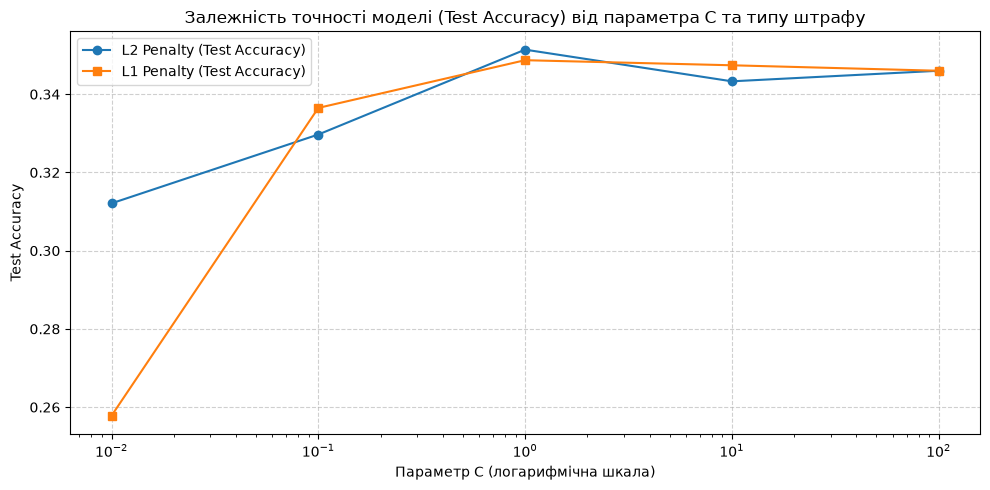

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(reg_df['C'], reg_df['L2 Test Acc'], marker='o', label='L2 Penalty (Test Accuracy)')
plt.plot(reg_df['C'], reg_df['L1 Test Acc'], marker='s', label='L1 Penalty (Test Accuracy)')
plt.xscale('log')
plt.title("Залежність точності моделі (Test Accuracy) від параметра C та типу штрафу", fontsize=12)
plt.xlabel("Параметр C (логарифмічна шкала)")
plt.ylabel("Test Accuracy")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig("outputs/fig_lab6_regularization_acc.png", dpi=120)
plt.show()

In [14]:
import numpy as np
import pandas as pd

print("ЧАСТИНА 3: Інтерпретація коефіцієнтів та відношення шансів (Odds Ratio)")

# Вказуємо назву класу українською мовою, як у le_target.classes_
target_class = 'квитанція'
class_idx = list(le_target.classes_).index(target_class)

# Вагові коефіцієнти для обраного класу з базової моделі
coefs_class = pd.Series(log_reg_base.coef_[class_idx], index=feature_names)

# Топ-5 найвпливовіших ознак за модулем
top5_idx = coefs_class.abs().sort_values(ascending=False).head(5).index
top5_coefs = coefs_class[top5_idx]

# Обчислення відношення шансів e^(w_i)
top5_odds = np.exp(top5_coefs)

interp_df = pd.DataFrame({
    'Коефіцієнт (w_i)': top5_coefs.round(4),
    'Відношення шансів e^(w_i)': top5_odds.round(4)
})

print(f"\nТоп-5 найвпливовіших ознак для класу '{target_class}':")
display(interp_df)

ЧАСТИНА 3: Інтерпретація коефіцієнтів та відношення шансів (Odds Ratio)

Топ-5 найвпливовіших ознак для класу 'квитанція':


,Коефіцієнт (w_i),Відношення шансів e^(w_i)
source_dataset_SROIE/CORD,2.5772,13.1600
authenticity_genuine,1.7760,5.9061
authenticity_not_applicable,-1.7643,0.1713
source_dataset_RVL-CDIP,-1.3164,0.2681
dark_pixel_ratio,1.1664,3.2103


In [15]:
print("ЧАСТИНА 4: Зведена порівняльна таблиця класифікаторів")

comparison_data = [
    {
        'Модель / Метод': 'k-NN (k=21) [Лаб. №3]',
        'Accuracy (Test)': 0.3962,
        'F1-macro (Test)': 0.4084,
        'Інтерпретованість': 'Низька',
        'Потребує масштабування': 'Так',
        'Час передбачення (с)': 0.016718
    },
    {
        'Модель / Метод': 'GaussianNB [Лаб. №4]',
        'Accuracy (Test)': 0.3297,
        'F1-macro (Test)': 0.3053,
        'Інтерпретованість': 'Середня',
        'Потребує масштабування': 'Ні',
        'Час передбачення (с)': 0.001834
    },
    {
        'Модель / Метод': 'DecisionTree (GridSearchCV) [Лаб. №5]',
        'Accuracy (Test)': 0.3677,
        'F1-macro (Test)': 0.3532,
        'Інтерпретованість': 'Висока',
        'Потребує масштабування': 'Ні',
        'Час передбачення (с)': 0.001296
    },
    {
        'Модель / Метод': 'LogisticRegression (Base) [Лаб. №6]',
        'Accuracy (Test)': round(test_acc_base, 4),
        'F1-macro (Test)': round(f1_base, 4),
        'Інтерпретованість': 'Висока',
        'Потребує масштабування': 'Так',
        'Час передбачення (с)': round(predict_time_base, 6)
    }
]

df_comparison = pd.DataFrame(comparison_data)
display(df_comparison)

ЧАСТИНА 4: Зведена порівняльна таблиця класифікаторів


,Модель / Метод,Accuracy (Test),F1-macro (Test),Інтерпретованість,Потребує масштабування,Час передбачення (с)
0,k-NN (k=21) [Лаб. №3],0.3962,0.4084,Низька,Так,0.016718
1,GaussianNB [Лаб. №4],0.3297,0.3053,Середня,Ні,0.001834
2,DecisionTree (GridSearchCV) [Лаб. №5],0.3677,0.3532,Висока,Ні,0.001296
3,LogisticRegression (Base) [Лаб. №6],0.3514,0.3293,Висока,Так,0.001181
